# 05 – Initialiser le HMM avec un LSTM (au lieu d'une initialisation aléatoire)

**Problème.** Pour entraîner un HMM, l'algorithme de Baum-Welch a besoin de **paramètres de départ** :
- **π** : la probabilité de chaque régime au départ ;
- **A** : la matrice de transition de la chaîne de Markov (probabilité de passer d'un régime à l'autre) ;
- **μ_k, Σ_k** : la moyenne et la covariance des observations dans chaque régime (lois d'émission gaussiennes).

Habituellement, ces paramètres sont tirés **au hasard**. Le notebook 03 a montré le défaut : selon le tirage, Baum-Welch peut s'arrêter dans un **optimum local**, et les résultats changent d'un essai à l'autre.

**Idée de ce notebook.** On remplace le hasard par un **LSTM** (réseau de neurones récurrent) entraîné sur **nos données** :
1. le LSTM lit les 10 derniers jours (30 bougies de 8 h) et apprend à **prévoir le rendement et la volatilité** de la suite ;
2. pour bien prévoir, il doit résumer l'état du marché dans sa **mémoire interne** `h_t` ;
3. on regroupe ces mémoires en **3 régimes** (k-means) ;
4. à partir de cette suite de régimes, on **compte** les transitions → **π et A**, et on calcule les moyennes / covariances → **μ_k et Σ_k** ;
5. ces paramètres servent de **point de départ** au HMM, puis Baum-Welch les affine.

| Section | Contenu |
|---|---|
| 1 | Bibliothèques et paramètres |
| 2 | Chargement des données (notebooks 01 et 02) |
| 3 | Variables d'entrée du LSTM et transformation gaussienne |
| 4 | Cibles du LSTM |
| 5 | Fenêtres glissantes et découpage train / validation |
| 6 | Architecture du LSTM |
| 7 | Entraînement et courbes d'apprentissage |
| 8 | Qualité des prévisions du LSTM |
| 9 | États cachés du LSTM et choix du nombre de régimes |
| 10 | Régimes trouvés par le LSTM |
| 11 | Paramètres de la chaîne de Markov : π et A |
| 12 | Paramètres d'émission : μ_k et Σ_k |
| 13 | HMM initialisé par le LSTM + Baum-Welch |
| 14 | Comparaison avec des initialisations aléatoires |
| 15 | Robustesse (autres graines du LSTM) |
| 16 | Régimes finaux et prédiction sans look-ahead sur le test |
| 17 | Sauvegarde et conclusion |

**Exécuter d'abord `01_donnees.ipynb` et `02_selection_features.ipynb`.** Chaque cellule de code est précédée d'une description et suivie d'une **interprétation**.

## 1. Bibliothèques et paramètres

### Cellule 1 – Bibliothèques, paramètres et graines aléatoires
Tous les réglages sont au même endroit. Les **graines aléatoires** (`GRAINE`) sont fixées pour que le notebook donne **exactement le même résultat** à chaque exécution : le LSTM part de poids tirés au hasard, et k-means aussi.

In [1]:
import sys, json, warnings
sys.path.append("../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from scipy import stats
from scipy.stats import multivariate_normal
from sklearn.preprocessing import QuantileTransformer, StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from hmmlearn.hmm import GaussianHMM
from fonctions import construire_candidates, construire_cibles
warnings.filterwarnings("ignore")
np.set_printoptions(precision=4, suppress=True)

DOSSIER  = "../data/btcusdt"   # fichiers produits par 01_donnees.ipynb
PAR_JOUR = 3                   # bougies de 8 h : 1 jour = 3 lignes
L        = 30                  # longueur d'une fenêtre : 30 bougies = 10 jours de passé
H        = 16                  # taille de la mémoire du LSTM (nombre de neurones)
N        = 3                   # nombre de régimes du HMM (sujet : 3 régimes)
VAL_FRAC = 0.15                # dernière part du train gardée pour la validation du LSTM
GRAINE   = 0                   # graine aléatoire (reproductibilité)
NOMS     = ["Calme", "Intermédiaire", "Agité"]   # régimes triés par volatilité croissante

torch.manual_seed(GRAINE); np.random.seed(GRAINE)
print("torch", torch.__version__, "| fenêtre :", L, "bougies =", L // PAR_JOUR, "jours | mémoire :", H, "| régimes :", N)

torch 2.15.0+cpu | fenêtre : 30 bougies = 10 jours | mémoire : 16 | régimes : 3


> **Interprétation :**
>
> Les bibliothèques sont chargées (PyTorch pour le LSTM, `hmmlearn` pour le HMM). Le LSTM lira des fenêtres de **30 bougies = 10 jours** et aura une mémoire de **16 neurones**. On cherche **3 régimes**, comme demandé dans le sujet.

## 2. Chargement des données

### Cellule 2 – Fichiers des notebooks 01 et 02
- `X_train` / `X_test` : les **observations du HMM** (rendement et volatilité), déjà transformées en loi normale N(0, 1) dans le notebook 01. On utilise exactement les mêmes que dans le notebook 04 pour pouvoir comparer.
- `btcusdt_features.csv` : toutes les features brutes et le prix.
- `features_selectionnees.json` : les variables retenues par la feature selection du notebook 02.

In [2]:
X_train_df = pd.read_csv(f"{DOSSIER}_X_train.csv", index_col=0, parse_dates=True)
X_test_df  = pd.read_csv(f"{DOSSIER}_X_test.csv",  index_col=0, parse_dates=True)
feat       = pd.read_csv(f"{DOSSIER}_features.csv", index_col=0, parse_dates=True)
selection  = json.load(open("../results/features_selectionnees.json", encoding="utf-8"))

colonnes = list(X_train_df.columns)
X_train, X_test = X_train_df.values, X_test_df.values
k = len(X_train)                                    # nombre de lignes du train
assert (feat.index[:k] == X_train_df.index).all() and (feat.index[k:] == X_test_df.index).all()
print("Observations du HMM :", colonnes)
print(f"train : {X_train_df.index[0]} -> {X_train_df.index[-1]} ({k} lignes)")
print(f"test  : {X_test_df.index[0]} -> {X_test_df.index[-1]} ({len(X_test)} lignes)")
print("Feature selection (notebook 02) :", selection)

Observations du HMM : ['rendement', 'volatilite']
train : 2017-09-06 00:00:00 -> 2024-02-01 16:00:00 (7014 lignes)
test  : 2024-02-02 00:00:00 -> 2026-10-31 16:00:00 (3009 lignes)
Feature selection (notebook 02) : {'rendement': ['rend_lag2'], 'volatilite': ['volatilite', 'vol_3j', 'amplitude'], 'close': ['log_close'], 'MACD': ['MACD_norm', 'RSI', 'histo_norm', 'rend_1sem']}


> **Interprétation :**
>
> On retrouve les mêmes données que dans les notebooks 01 et 04 : **7 014 bougies de train** (septembre 2017 → février 2024) et **3 009 bougies de test** (février 2024 → octobre 2026). Les observations du HMM sont toujours le **rendement** et la **volatilité**.
> La feature selection du notebook 02 est relue : pour la volatilité, les variables utiles sont `volatilite`, `vol_3j` et `amplitude`.

## 3. Variables d'entrée du LSTM

### Cellule 3 – Choix des variables d'entrée à partir de la feature selection
Le notebook 02 a montré que la seule chose vraiment prévisible est la **volatilité**, et que les variables qui l'influencent sont `volatilite`, `vol_3j` et `amplitude`. On les donne au LSTM, avec le `rendement` (la direction du marché, qui est aussi une observation du HMM).

In [3]:
ENTREES = ["rendement"] + [v for v in selection["volatilite"] if v != "rendement"]
candidates = construire_candidates(feat, feat, PAR_JOUR)       # mêmes variables que dans le notebook 02
E = candidates[ENTREES]
print("Variables d'entrée du LSTM :", ENTREES)
print("Valeurs manquantes (début de série, fenêtres glissantes) :")
print(E.isna().sum().to_string())
E.describe().T.round(4)

Variables d'entrée du LSTM : ['rendement', 'volatilite', 'vol_3j', 'amplitude']
Valeurs manquantes (début de série, fenêtres glissantes) :
rendement     0
volatilite    0
vol_3j        8
amplitude     0


,count,mean,std,min,25%,50%,75%,max
rendement,10023.0,0.0003,0.0200,-0.2449,-0.0070,0.0004,0.0078,0.1961
volatilite,10023.0,0.0179,0.0091,0.0041,0.0118,0.0158,0.0210,0.0576
vol_3j,10015.0,0.0165,0.0114,0.0008,0.0091,0.0138,0.0203,0.1151
amplitude,10023.0,0.0276,0.0238,0.0015,0.0134,0.0211,0.0336,0.3792


> **Interprétation :**
>
> Le LSTM reçoit **4 variables** : le rendement et les 3 variables qui influencent la volatilité d'après le notebook 02.
> `vol_3j` a **8 valeurs manquantes** au début (il faut 9 bougies pour la calculer). Les fenêtres qui les contiennent seront écartées.
> Les échelles sont très différentes (rendement ≈ 0 ± 2 %, amplitude jusqu'à 38 %) : il faut les mettre à la même échelle avant le réseau.

### Cellule 4 – Transformation gaussienne des entrées (ajustée sur le train)
Comme dans le notebook 01, on transforme chaque variable vers une **loi normale N(0, 1)** avec `QuantileTransformer`, **ajusté sur le train uniquement**. Un réseau de neurones apprend mieux quand toutes les entrées ont la même échelle et pas de valeurs extrêmes.

In [4]:
qt = QuantileTransformer(output_distribution="normal", n_quantiles=1000, random_state=GRAINE)
qt.fit(E.iloc[:k].dropna())                                     # TRAIN seulement
Ez = pd.DataFrame(qt.transform(E.fillna(0)), index=E.index, columns=ENTREES)
Ez[E.isna().any(axis=1)] = np.nan                               # on garde les trous du début

verif = pd.DataFrame({"asymétrie": Ez.iloc[:k].apply(lambda s: stats.skew(s.dropna())),
                      "kurtosis en excès": Ez.iloc[:k].apply(lambda s: stats.kurtosis(s.dropna())),
                      "moyenne": Ez.iloc[:k].mean(), "écart-type": Ez.iloc[:k].std()})
verif.round(3)

,asymétrie,kurtosis en excès,moyenne,écart-type
rendement,0.003,0.122,0.0,1.002
volatilite,-0.004,0.113,-0.0,1.002
vol_3j,-0.001,0.148,-0.0,1.003
amplitude,-0.003,0.114,-0.0,1.002


> **Interprétation :**
>
> Après la transformation, les 4 variables du train ont une **moyenne 0, un écart-type 1**, une asymétrie et une kurtosis en excès **proches de 0** : elles suivent une **loi normale N(0, 1)**. Toutes les entrées ont la même échelle, sans valeurs extrêmes qui perturberaient l'apprentissage du réseau.

## 4. Cibles du LSTM

### Cellule 5 – Ce que le LSTM doit prévoir
Le LSTM ne prévoit pas les régimes directement : on ne les connaît pas (ils sont **cachés**). On lui demande de prévoir deux quantités **observables** dans le futur (fonction `construire_cibles`, la même que dans le notebook 02) :
- `rendement` : le rendement de la **bougie suivante** ;
- `log_vol` : le **log de la volatilité réalisée de la journée suivante** (bougies t+1, t+2, t+3). Le log rend cette variable plus symétrique.

Les deux cibles sont standardisées (moyenne 0, écart-type 1 sur le train) pour qu'elles comptent autant l'une que l'autre dans l'erreur.

In [5]:
cibles = construire_cibles(feat, feat, PAR_JOUR)
Y = pd.DataFrame({"rendement": cibles["rendement"], "log_vol": np.log(cibles["volatilite"])})
y_scaler = StandardScaler().fit(Y.iloc[:k].dropna())            # TRAIN seulement
Yz = pd.DataFrame(y_scaler.transform(Y), index=Y.index, columns=Y.columns)
print("Cibles manquantes (fin de série : pas de futur) :", Y.isna().sum().to_dict())
pd.DataFrame({"moyenne brute (train)": Y.iloc[:k].mean(), "écart-type brut (train)": Y.iloc[:k].std(),
              "corrélation avec la valeur actuelle": [Y["rendement"].corr(feat["rendement"]),
                                                      Y["log_vol"].corr(np.log(candidates["vol_jour"]))]}).round(4)

Cibles manquantes (fin de série : pas de futur) : {'rendement': 1, 'log_vol': 3}


,moyenne brute (train),écart-type brut (train),corrélation avec la valeur actuelle
rendement,0.0003,0.0222,-0.0160
log_vol,-4.4319,0.8617,0.3854


> **Interprétation :**
>
> - Il manque la cible pour la toute fin de la série (1 bougie pour le rendement, 3 pour la volatilité de la journée suivante) : il n'y a pas de futur après le 31 octobre 2026. Ces lignes sont dans le test, elles ne gênent pas l'entraînement.
> - **Rendement suivant :** sa corrélation avec le rendement actuel est **−0,02**, presque nulle : il est quasiment imprévisible.
> - **Log-volatilité du jour suivant :** sa corrélation avec la volatilité des dernières 24 h est **0,39** : la volatilité future dépend nettement de la volatilité passée. C'est surtout cela que le LSTM pourra apprendre.

## 5. Fenêtres glissantes et découpage

### Cellule 6 – Construction des fenêtres de 30 bougies
Un LSTM lit une **séquence**. Pour chaque bougie `t`, on prend les 30 dernières bougies `[t−29, …, t]` (10 jours) : c'est l'entrée. La cible est le futur de `t`. On ne garde que les fenêtres **complètes** (sans valeur manquante).

Format obtenu : `(nombre de fenêtres, 30 pas de temps, 4 variables)`. Le train et le test sont séparés **au même endroit** que dans le notebook 01 : aucune fenêtre du train ne contient de cible du test.

In [6]:
def fenetres(debut, fin):
    # Pour chaque t de [debut, fin[ : fenêtre Ez[t-L+1 .. t] et cible Yz[t]
    idx, Xs, Ys = [], [], []
    for t in range(max(debut, L - 1), fin):
        w = Ez.values[t - L + 1:t + 1]
        if np.isnan(w).any():
            continue
        idx.append(t); Xs.append(w); Ys.append(Yz.values[t])
    return np.array(idx), np.array(Xs, dtype=np.float32), np.array(Ys, dtype=np.float32)

i_tr, W_tr, Y_tr = fenetres(0, k)            # fenêtres du train
i_te, W_te, Y_te = fenetres(k, len(Ez))      # fenêtres du test
print("Fenêtres train :", W_tr.shape, "| première bougie couverte :", feat.index[i_tr[0]])
print("Fenêtres test  :", W_te.shape, "| première bougie couverte :", feat.index[i_te[0]])
print("Cibles manquantes dans le train :", int(np.isnan(Y_tr).any(axis=1).sum()))
print("\nExemple : fenêtre n°0, 3 dernières bougies (variables transformées)")
print(pd.DataFrame(W_tr[0, -3:], columns=ENTREES, index=feat.index[i_tr[0] - 2:i_tr[0] + 1]).round(3))

Fenêtres train : (6977, 30, 4) | première bougie couverte : 2017-09-18 08:00:00
Fenêtres test  : (3009, 30, 4) | première bougie couverte : 2024-02-02 00:00:00


Cibles manquantes dans le train : 0

Exemple : fenêtre n°0, 3 dernières bougies (variables transformées)
                     rendement  volatilite  vol_3j  amplitude
Date                                                         
2017-09-17 16:00:00      1.079       1.728   2.466      0.328
2017-09-18 00:00:00      2.366       1.763   2.472      1.660
2017-09-18 08:00:00      1.206       1.738   1.961      1.486


> **Interprétation :**
>
> - **6 977 fenêtres de train** : les 37 premières bougies sont perdues (8 pour `vol_3j` et 29 pour remplir la première fenêtre). La première fenêtre complète se termine le 18 septembre 2017 à 08h.
> - **3 009 fenêtres de test** : une par bougie du test. Les fenêtres du début du test utilisent la fin du train comme passé, ce qui est permis (c'est du passé connu), mais leurs cibles sont toutes dans le test.
> - Chaque fenêtre est un tableau **30 × 4**. L'exemple montre la fin de la première fenêtre : en septembre 2017, la volatilité transformée est vers +1,7 (marché très agité, haut de la distribution).

### Cellule 7 – Découpage train / validation (chronologique)
Pour savoir **quand arrêter l'entraînement** (sinon le LSTM apprend par cœur), on garde les **15 % les plus récents du train** comme validation. Le découpage est **chronologique** (pas de mélange) : on valide toujours sur une période **postérieure** à celle d'apprentissage, comme dans la réalité. Le test (2024-2026) n'est **jamais** utilisé ici.

In [7]:
ok = ~np.isnan(Y_tr).any(axis=1)
Xa, Ya = torch.tensor(W_tr[ok]), torch.tensor(Y_tr[ok])
nv = int(len(Xa) * VAL_FRAC)
X_fit, Y_fit, X_val, Y_val = Xa[:-nv], Ya[:-nv], Xa[-nv:], Ya[-nv:]
dates_ok = feat.index[i_tr[ok]]
print(f"apprentissage : {len(X_fit)} fenêtres ({dates_ok[0].date()} -> {dates_ok[-nv - 1].date()})")
print(f"validation    : {len(X_val)} fenêtres ({dates_ok[-nv].date()} -> {dates_ok[-1].date()})")

apprentissage : 5931 fenêtres (2017-09-18 -> 2023-02-18)
validation    : 1046 fenêtres (2023-02-18 -> 2024-02-01)


> **Interprétation :**
>
> - **Apprentissage : 5 931 fenêtres** (septembre 2017 → février 2023) ;
> - **Validation : 1 046 fenêtres** (février 2023 → février 2024), environ 1 an.
>
> La validation est **après** l'apprentissage dans le temps, et le test 2024-2026 reste entièrement de côté.

## 6. Architecture du LSTM

### Cellule 8 – Le réseau
Un LSTM lit la fenêtre bougie par bougie et met à jour deux mémoires : `c_t` (mémoire longue) et `h_t` (état caché). À chaque pas :
- **porte d'oubli** `f_t = σ(W_f [h_{t−1}, x_t] + b_f)` : ce qu'on efface de la mémoire ;
- **porte d'entrée** `i_t = σ(W_i [h_{t−1}, x_t] + b_i)` et candidat `c̃_t = tanh(W_c [h_{t−1}, x_t] + b_c)` : ce qu'on ajoute ;
- **mise à jour** `c_t = f_t ⊙ c_{t−1} + i_t ⊙ c̃_t` ;
- **porte de sortie** `o_t = σ(W_o [h_{t−1}, x_t] + b_o)` et `h_t = o_t ⊙ tanh(c_t)`.

Après la 30ᵉ bougie, `h_t` (16 nombres) **résume les 10 derniers jours**. Une couche linéaire transforme `h_t` en prévision des 2 cibles. C'est ce vecteur `h_t` qu'on utilisera pour trouver les régimes.

In [8]:
class ReseauLSTM(nn.Module):
    def __init__(self, d_entree, d_cache):
        super().__init__()
        self.lstm = nn.LSTM(d_entree, d_cache, batch_first=True)
        self.tete = nn.Linear(d_cache, 2)              # 2 cibles : rendement suivant, log-volatilité du jour suivant

    def forward(self, x):
        sorties, (h_T, c_T) = self.lstm(x)
        h = h_T[-1]                                    # état caché après la dernière bougie de la fenêtre
        return self.tete(h), h

torch.manual_seed(GRAINE)
modele = ReseauLSTM(len(ENTREES), H)
print(modele)
for nom, p in modele.named_parameters():
    print(f"  {nom:22s} {tuple(p.shape)}")
print("Nombre total de paramètres :", sum(p.numel() for p in modele.parameters()))

ReseauLSTM(
  (lstm): LSTM(4, 16, batch_first=True)
  (tete): Linear(in_features=16, out_features=2, bias=True)
)
  lstm.weight_ih_l0      (64, 4)
  lstm.weight_hh_l0      (64, 16)
  lstm.bias_ih_l0        (64,)
  lstm.bias_hh_l0        (64,)
  tete.weight            (2, 16)
  tete.bias              (2,)
Nombre total de paramètres : 1442


> **Interprétation :**
>
> Le réseau a **1 442 paramètres** :
> - la couche LSTM a des matrices de taille **64** = 4 portes × 16 neurones (oubli, entrée, candidat, sortie), appliquées à l'entrée (4 variables) et à la mémoire précédente (16) ;
> - la couche linéaire finale transforme les 16 nombres de `h_t` en **2 prévisions**.
>
> C'est un petit réseau : avec environ 6 000 fenêtres, un réseau beaucoup plus gros risquerait d'apprendre le bruit par cœur.

## 7. Entraînement

### Cellule 9 – Entraînement avec arrêt anticipé (early stopping)
- **Erreur** : erreur quadratique moyenne (MSE) entre la prévision et la vraie valeur des 2 cibles.
- **Optimiseur** : Adam, taux d'apprentissage 0,001, paquets de 128 fenêtres mélangés à chaque époque.
- **Arrêt anticipé** : après chaque époque on mesure l'erreur sur la validation ; si elle ne baisse plus pendant 10 époques, on s'arrête et on **reprend les poids de la meilleure époque**.

In [9]:
def entrainer(modele, X_fit, Y_fit, X_val, Y_val, graine=GRAINE, max_epoques=100, patience=10, afficher=True):
    torch.manual_seed(graine)
    opt, perte = torch.optim.Adam(modele.parameters(), lr=1e-3), nn.MSELoss()
    gen = torch.Generator().manual_seed(graine)
    meilleure, meilleurs_poids, attente, historique = np.inf, None, 0, []
    for ep in range(1, max_epoques + 1):
        modele.train()
        ordre = torch.randperm(len(X_fit), generator=gen)
        for b in range(0, len(X_fit), 128):
            j = ordre[b:b + 128]
            opt.zero_grad(); l = perte(modele(X_fit[j])[0], Y_fit[j]); l.backward(); opt.step()
        modele.eval()
        with torch.no_grad():
            l_fit, l_val = perte(modele(X_fit)[0], Y_fit).item(), perte(modele(X_val)[0], Y_val).item()
        historique.append({"époque": ep, "erreur apprentissage": l_fit, "erreur validation": l_val})
        if l_val < meilleure - 1e-5:
            meilleure, attente = l_val, 0
            meilleurs_poids = {n: v.clone() for n, v in modele.state_dict().items()}
        else:
            attente += 1
        if afficher and (ep % 5 == 0 or ep == 1):
            print(f"époque {ep:3d} | erreur apprentissage {l_fit:.4f} | erreur validation {l_val:.4f}")
        if attente >= patience:
            break
    modele.load_state_dict(meilleurs_poids)
    return pd.DataFrame(historique).set_index("époque")

hist = entrainer(modele, X_fit, Y_fit, X_val, Y_val)
print(f"\nArrêt à l'époque {hist.index[-1]} ; meilleure époque : {hist['erreur validation'].idxmin()} "
      f"(erreur validation {hist['erreur validation'].min():.4f})")

époque   1 | erreur apprentissage 0.9104 | erreur validation 0.6322


époque   5 | erreur apprentissage 0.8804 | erreur validation 0.6026


époque  10 | erreur apprentissage 0.8691 | erreur validation 0.5930


époque  15 | erreur apprentissage 0.8642 | erreur validation 0.6018


époque  20 | erreur apprentissage 0.8612 | erreur validation 0.6040


époque  25 | erreur apprentissage 0.8557 | erreur validation 0.5904


époque  30 | erreur apprentissage 0.8527 | erreur validation 0.5853


époque  35 | erreur apprentissage 0.8479 | erreur validation 0.5938


époque  40 | erreur apprentissage 0.8494 | erreur validation 0.6225


époque  45 | erreur apprentissage 0.8370 | erreur validation 0.5874



Arrêt à l'époque 49 ; meilleure époque : 39 (erreur validation 0.5839)


> **Interprétation :**
>
> - L'erreur d'apprentissage baisse régulièrement (0,91 → 0,84) : le réseau apprend.
> - L'erreur de validation baisse surtout pendant les premières époques (0,63 → 0,59), puis oscille autour de 0,59.
> - Le meilleur score de validation est atteint à l'**époque 39** (0,584). Après 10 époques sans amélioration, l'entraînement s'arrête à l'époque 49 et on reprend les poids de l'époque 39.

### Cellule 10 – Courbes d'apprentissage
L'erreur d'apprentissage doit baisser. L'erreur de validation doit baisser puis se stabiliser ; si elle remontait pendant que l'autre baisse, ce serait du **sur-apprentissage**. Sauvegardé dans `results/lstm_apprentissage.png`.

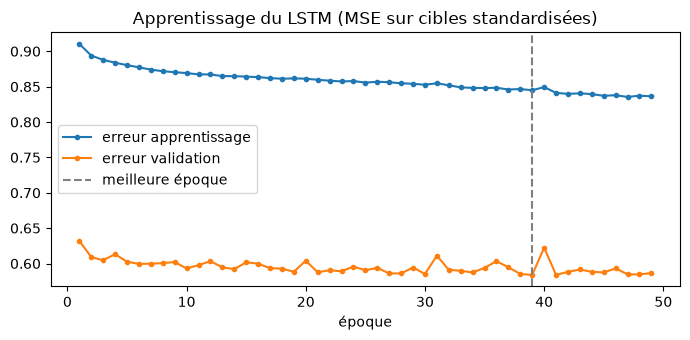

In [10]:
ax = hist.plot(figsize=(7, 3.5), marker=".", title="Apprentissage du LSTM (MSE sur cibles standardisées)")
ax.axvline(hist["erreur validation"].idxmin(), color="grey", ls="--", label="meilleure époque")
ax.legend(); plt.tight_layout(); plt.savefig("../results/lstm_apprentissage.png", dpi=150); plt.show()

> **Interprétation :**
>
> - Les deux courbes ne remontent pas : il n'y a **pas de sur-apprentissage** marqué. L'arrêt anticipé garde le meilleur modèle (ligne pointillée).
> - L'erreur de validation est **plus basse** que celle d'apprentissage. Ce n'est pas une erreur : la période de validation (2023) est **beaucoup plus calme** que 2017-2022, donc ses valeurs sont plus faciles à prévoir (moins de chocs extrêmes).
> - L'erreur reste assez élevée (≈ 0,6 à 0,85 sur des cibles d'écart-type 1) : une grande partie du futur reste imprévisible, surtout le rendement.

## 8. Qualité des prévisions du LSTM

### Cellule 11 – Le LSTM a-t-il appris quelque chose ?
On compare l'erreur (RMSE) du LSTM sur la validation avec deux prévisions **naïves** :
- **moyenne** : prévoir toujours la moyenne du train (0 après standardisation) ;
- **persistance** : prévoir que demain ressemble à aujourd'hui (rendement actuel ; volatilité des dernières 24 h).

Si le LSTM ne bat pas les naïfs, sa mémoire `h_t` ne contient rien d'utile et ne peut pas servir à trouver des régimes.

In [11]:
with torch.no_grad():
    pred_val = modele(X_val)[0].numpy()
vrai = Y_val.numpy()
t_val = i_tr[ok][-nv:]
pers = y_scaler.transform(pd.DataFrame({"rendement": feat["rendement"].values[t_val],
                                        "log_vol": np.log(candidates["vol_jour"].values[t_val])}))
rmse = lambda p, y: np.sqrt(((p - y) ** 2).mean(axis=0))
qualite = pd.DataFrame({"LSTM": rmse(pred_val, vrai), "naïf : moyenne": rmse(0 * vrai, vrai),
                        "naïf : persistance": rmse(pers, vrai)}, index=["rendement suivant", "log-volatilité du jour suivant"])
qualite["gain du LSTM vs moyenne (%)"] = 100 * (1 - qualite["LSTM"] / qualite["naïf : moyenne"])
qualite["gain du LSTM vs persistance (%)"] = 100 * (1 - qualite["LSTM"] / qualite["naïf : persistance"])
qualite.round(3)

,LSTM,naïf : moyenne,naïf : persistance,gain du LSTM vs moyenne (%),gain du LSTM vs persistance (%)
rendement suivant,0.568,0.566,0.780,-0.435000,27.157
log-volatilité du jour suivant,0.919,1.146,1.183,19.823999,22.321


> **Interprétation :**
>
> - **Rendement suivant :** le LSTM fait **comme la moyenne** (0,568 contre 0,566). Il n'arrive pas à prévoir la direction du prix, exactement comme la feature selection du notebook 02 l'avait montré. Il bat la persistance, mais seulement parce que « répéter le rendement d'aujourd'hui » est une très mauvaise prévision.
> - **Log-volatilité du jour suivant :** le LSTM réduit l'erreur de **20 %** par rapport à la moyenne et de **22 %** par rapport à la persistance. Il a donc appris quelque chose de réel : **le niveau de volatilité du marché**.
>
> Conclusion : la mémoire `h_t` du LSTM contient une information utile sur **l'état du marché (calme ou agité)**. C'est exactement ce qu'un régime doit décrire, et c'est pourquoi on peut s'en servir pour construire les paramètres du HMM.

## 9. États cachés du LSTM

### Cellule 12 – Extraction de la mémoire `h_t` pour chaque bougie du train
On passe **toutes** les fenêtres du train dans le LSTM entraîné et on récupère le vecteur `h_t` (16 nombres) de chacune. On les standardise, puis on les projette en 2 dimensions (ACP) pour les visualiser, coloriés par la volatilité du moment.

États cachés du train : (6977, 16) | variance expliquée par les 2 axes de l'ACP : [0.493 0.162] total 0.654


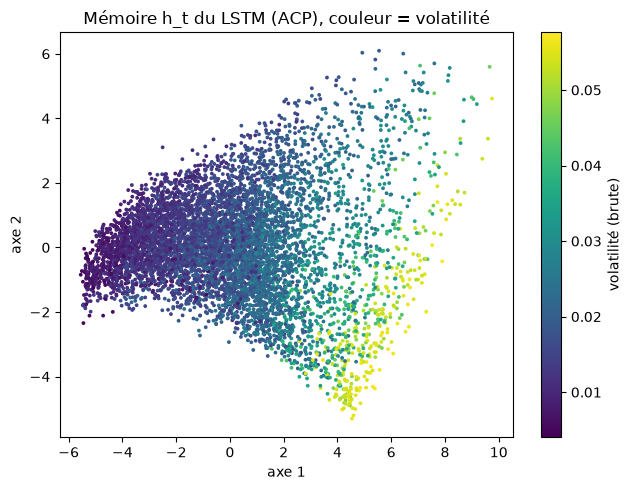

In [12]:
modele.eval()
with torch.no_grad():
    H_tr = modele(torch.tensor(W_tr))[1].numpy()
h_scaler = StandardScaler().fit(H_tr)
Hs_tr = h_scaler.transform(H_tr)

acp = PCA(2, random_state=GRAINE).fit(Hs_tr)
P = acp.transform(Hs_tr)
print("États cachés du train :", H_tr.shape, "| variance expliquée par les 2 axes de l'ACP :",
      acp.explained_variance_ratio_.round(3), "total", acp.explained_variance_ratio_.sum().round(3))
plt.figure(figsize=(6.5, 5))
sc = plt.scatter(P[:, 0], P[:, 1], c=feat["volatilite"].values[i_tr], s=3, cmap="viridis")
plt.colorbar(sc, label="volatilité (brute)"); plt.xlabel("axe 1"); plt.ylabel("axe 2")
plt.title("Mémoire h_t du LSTM (ACP), couleur = volatilité")
plt.tight_layout(); plt.savefig("../results/lstm_etats_acp.png", dpi=150); plt.show()

> **Interprétation :**
>
> - Chaque point est une bougie du train, placée selon les 2 premiers axes de l'ACP de sa mémoire `h_t`. Ces 2 axes résument **65 %** de l'information des 16 dimensions (49 % pour le premier).
> - La couleur va du violet (volatilité faible) au jaune (volatilité forte) **de gauche à droite** : le premier axe de la mémoire du LSTM est essentiellement un **axe de volatilité**.
> - Les points ne forment pas des paquets bien séparés, mais un **nuage continu** : on passe progressivement du calme à l'agitation. Le découpage en régimes sera donc en partie une convention.

### Cellule 13 – Combien de régimes ? (score de silhouette)
On regroupe les `h_t` avec **k-means** pour 2 à 5 groupes. Le **score de silhouette** (entre −1 et 1) mesure si les groupes sont bien séparés : plus il est haut, mieux c'est. k-means utilise 10 départs et une graine fixe : il est **déterministe**.

In [13]:
sil = {}
for n in range(2, 6):
    km_n = KMeans(n, n_init=10, random_state=GRAINE).fit(Hs_tr)
    sil[n] = silhouette_score(Hs_tr, km_n.labels_, sample_size=3000, random_state=GRAINE)
pd.Series(sil, name="silhouette").rename_axis("nombre de régimes").round(3).to_frame()

,silhouette
nombre de régimes,
2,0.282
3,0.275
4,0.277
5,0.231


> **Interprétation :**
>
> Le score de silhouette est **faible et presque égal** pour 2, 3 et 4 régimes (0,28 ; 0,275 ; 0,28), puis baisse à 5 (0,23). Cela confirme le graphique précédent : les états du marché forment un **continuum**, il n'y a pas de frontière naturelle.
> Puisque 3 régimes sont aussi bons que 2 ou 4, on garde **N = 3**, comme le demande le sujet.

## 10. Régimes trouvés par le LSTM

### Cellule 14 – Régimes du LSTM (k-means à 3 groupes), triés par volatilité
On garde **N = 3** régimes. Les numéros donnés par k-means sont arbitraires : on les **trie par volatilité moyenne croissante** (0 = Calme, 1 = Intermédiaire, 2 = Agité) pour que la lecture soit toujours la même. Le tableau donne, pour chaque régime, les valeurs **brutes** (en %) du rendement et de la volatilité, et la durée moyenne d'un passage.

In [14]:
km = KMeans(N, n_init=10, random_state=GRAINE).fit(Hs_tr)
obs_tr = X_train[i_tr]                                        # observations du HMM aux mêmes bougies
ordre_vol = np.argsort([obs_tr[km.labels_ == c, 1].mean() for c in range(N)])
renum = np.argsort(ordre_vol)                                 # ancien numéro -> nouveau numéro
etiq = renum[km.labels_]                                      # régime LSTM de chaque bougie du train

def duree_moyenne(lab, c):
    # durée moyenne (en bougies) des passages consécutifs dans le régime c
    runs, n = [], 0
    for x in lab:
        if x == c: n += 1
        elif n: runs.append(n); n = 0
    if n: runs.append(n)
    return np.mean(runs)

brut = feat.iloc[i_tr]
resume_lstm = pd.DataFrame({
    "nb de bougies": np.bincount(etiq, minlength=N),
    "part du temps (%)": 100 * np.bincount(etiq, minlength=N) / len(etiq),
    "rendement moyen (%)": [100 * brut["rendement"].values[etiq == c].mean() for c in range(N)],
    "volatilité moyenne (%)": [100 * brut["volatilite"].values[etiq == c].mean() for c in range(N)],
    "durée moyenne (jours)": [duree_moyenne(etiq, c) / PAR_JOUR for c in range(N)]}, index=NOMS)
resume_lstm.round(3)

,nb de bougies,part du temps (%),rendement moyen (%),volatilité moyenne (%),durée moyenne (jours)
Calme,2464,35.316,0.052,1.242,6.417
Intermédiaire,3551,50.896,0.151,2.048,5.237
Agité,962,13.788,-0.443,3.657,3.239


> **Interprétation :**
>
> Les 3 régimes trouvés par le LSTM :
> - **Calme** (35 % du temps) : volatilité de **1,2 %**, rendement légèrement positif (0,05 % par bougie) ;
> - **Intermédiaire** (51 % du temps) : volatilité de **2,0 %**, le meilleur rendement moyen (0,15 % par bougie) ;
> - **Agité** (14 % du temps) : volatilité de **3,7 %**, et **rendement moyen négatif (−0,44 % par bougie)** : c'est le régime des chutes brutales, celui qui ressemble le plus à la **« Panique »** du sujet.
>
> Les passages durent **3 à 6 jours** en moyenne : le LSTM change de régime assez souvent, car il réagit aux 10 derniers jours.

### Cellule 15 – Les régimes du LSTM sur le prix (train)
Le prix du Bitcoin pendant la période d'apprentissage, colorié selon le régime trouvé par le LSTM. Sauvegardé dans `results/lstm_regimes_train.png`.

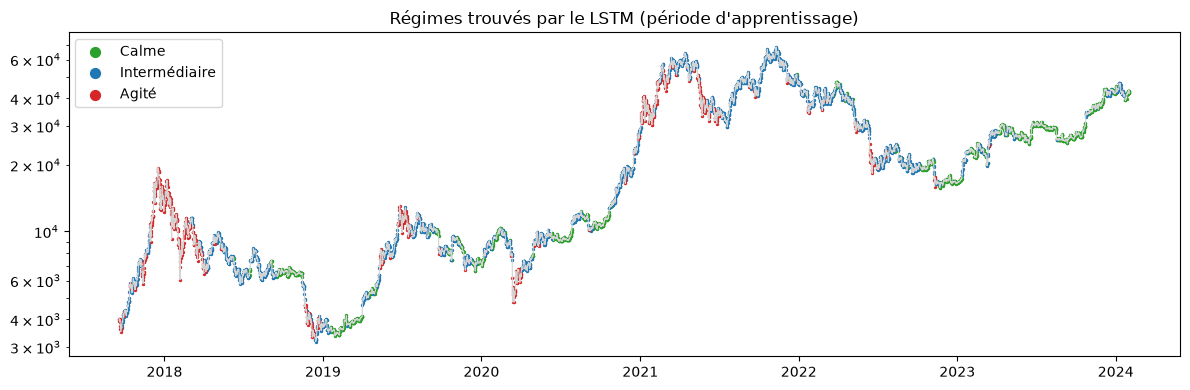

In [15]:
COULEURS = {"Calme": "tab:green", "Intermédiaire": "tab:blue", "Agité": "tab:red"}
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(brut.index, brut["Close"], color="lightgrey", lw=0.8)
for c, nom in enumerate(NOMS):
    sel = etiq == c
    ax.scatter(brut.index[sel], brut["Close"].values[sel], s=2, color=COULEURS[nom], label=nom)
ax.set_yscale("log"); ax.legend(markerscale=5); ax.set_title("Régimes trouvés par le LSTM (période d'apprentissage)")
plt.tight_layout(); plt.savefig("../results/lstm_regimes_train.png", dpi=150); plt.show()

> **Interprétation :**
>
> - Le **rouge (Agité)** tombe sur les grands épisodes de stress : la bulle et le krach de fin 2017 - début 2018, la chute de novembre 2018, le **krach du Covid (mars 2020)**, la chute de mai 2021 et l'effondrement de **juin 2022** (Terra/Luna, Celsius).
> - Le **vert (Calme)** couvre les périodes plates : été 2018, début 2019, fin 2020, et une grande partie de **2023**.
> - Le **bleu (Intermédiaire)** couvre la majorité des tendances, en hausse comme en baisse.
>
> Les régimes du LSTM ont donc un **sens économique clair**, sans qu'on lui ait jamais dit ce qu'est une crise.

## 11. Paramètres de la chaîne de Markov à partir du LSTM

### Cellule 16 – Distribution initiale π
On a **une seule** série, donc un seul « premier régime » : estimer π avec cette seule valeur donnerait 1 pour un régime et 0 pour les autres, ce qui est trop extrême. On prend donc la **fréquence de chaque régime** dans la suite trouvée par le LSTM :

`π_i = (nombre de bougies dans le régime i) / (nombre total de bougies)`.

In [16]:
pi_lstm = np.bincount(etiq, minlength=N) / len(etiq)
print("Premier régime de la série :", NOMS[etiq[0]])
pd.Series(pi_lstm, index=NOMS, name="π (LSTM)").round(4).to_frame()

Premier régime de la série : Agité


,π (LSTM)
Calme,0.3532
Intermédiaire,0.5090
Agité,0.1379


> **Interprétation :**
>
> π = **(0,35 ; 0,51 ; 0,14)** : au départ, le HMM considérera que le marché a 51 % de chances d'être dans le régime Intermédiaire et seulement 14 % d'être Agité.
> La première bougie de la série (septembre 2017) est dans le régime Agité. Si on avait pris uniquement ce premier régime, π aurait été (0 ; 0 ; 1), ce qui est beaucoup trop extrême pour une seule observation.

### Cellule 17 – Matrice de comptage des transitions
On parcourt la suite des régimes du LSTM et on compte, pour chaque couple (i, j), le nombre de fois où le régime `i` est **suivi** du régime `j` à la bougie suivante : c'est `n_ij`.

In [17]:
comptes = np.zeros((N, N), dtype=int)
for a, b in zip(etiq[:-1], etiq[1:]):
    comptes[a, b] += 1
pd.DataFrame(comptes, index=[f"de {n}" for n in NOMS], columns=[f"vers {n}" for n in NOMS])

,vers Calme,vers Intermédiaire,vers Agité
de Calme,2336,127,0
de Intermédiaire,128,3325,98
de Agité,0,99,863


> **Interprétation :**
>
> - La **diagonale** est très grande (2 336, 3 325, 863) : la plupart du temps, le régime de la bougie suivante est le **même**.
> - **Calme → Agité** et **Agité → Calme** : **0 fois**. Le marché ne saute jamais directement du calme à l'agitation : il passe toujours par l'**Intermédiaire**. C'est une « échelle » de volatilité qu'on monte et qu'on descend marche par marche.
> - Les passages Calme ↔ Intermédiaire (127 et 128) et Intermédiaire ↔ Agité (98 et 99) sont presque **symétriques** : autant d'entrées que de sorties.

### Cellule 18 – Matrice de transition A (maximum de vraisemblance + lissage)
L'estimateur du maximum de vraisemblance d'une chaîne de Markov est : `a_ij = n_ij / Σ_j n_ij` (part des sorties du régime `i` qui vont vers `j`).

On ajoute **1 à chaque case** avant de diviser (**lissage de Laplace**) : une transition jamais vue recevrait sinon une probabilité exactement nulle, et Baum-Welch ne pourrait **jamais** la rendre positive. On en déduit aussi la **durée moyenne** `1 / (1 − a_ii)` et la **distribution stationnaire** (long terme).

In [18]:
A_lstm = (comptes + 1) / (comptes + 1).sum(axis=1, keepdims=True)
assert np.allclose(A_lstm.sum(axis=1), 1)
display(pd.DataFrame(A_lstm, index=[f"de {n}" for n in NOMS], columns=[f"vers {n}" for n in NOMS]).round(4))

vals, vecs = np.linalg.eig(A_lstm.T)
stat = np.real(vecs[:, np.argmin(abs(vals - 1))]); stat /= stat.sum()
pd.DataFrame({"a_ii (rester)": np.diag(A_lstm), "durée moyenne (jours)": 1 / (1 - np.diag(A_lstm)) / PAR_JOUR,
              "distribution stationnaire": stat, "π (LSTM)": pi_lstm}, index=NOMS).round(4)

,vers Calme,vers Intermédiaire,vers Agité
de Calme,0.9477,0.0519,0.0004
de Intermédiaire,0.0363,0.9358,0.0279
de Agité,0.0010,0.1036,0.8953


,a_ii (rester),durée moyenne (jours),distribution stationnaire,π (LSTM)
Calme,0.9477,6.3721,0.3553,0.3532
Intermédiaire,0.9358,5.1959,0.5081,0.5090
Agité,0.8953,3.1848,0.1366,0.1379


> **Interprétation :**
>
> - On reste dans le même régime avec une probabilité de **0,95 (Calme)**, **0,94 (Intermédiaire)** et **0,90 (Agité)** : les régimes sont **persistants**, et l'agitation est le régime le moins stable.
> - Grâce au lissage, les transitions jamais observées valent **0,0004 et 0,001** au lieu de 0 : Baum-Welch pourra encore les modifier si les données le demandent.
> - Durées moyennes : **6,4 jours** (Calme), **5,2 jours** (Intermédiaire), **3,2 jours** (Agité).
> - La distribution stationnaire (0,355 ; 0,508 ; 0,137) est presque **identique à π** : la chaîne estimée est cohérente avec les fréquences observées.

## 12. Paramètres d'émission à partir du LSTM

### Cellule 19 – Moyennes μ_k et covariances Σ_k de chaque régime
Pour chaque régime `k` trouvé par le LSTM, on prend les **observations du HMM** (rendement et volatilité transformés, les mêmes que dans le notebook 04) des bougies de ce régime, et on calcule :
- `μ_k` = leur moyenne ;
- `Σ_k` = leur matrice de covariance.

Ce sont les paramètres des lois normales d'émission `N(μ_k, Σ_k)`.

In [19]:
mu_lstm  = np.array([obs_tr[etiq == c].mean(axis=0) for c in range(N)])
cov_lstm = np.array([np.cov(obs_tr[etiq == c].T) for c in range(N)])
display(pd.DataFrame(mu_lstm, index=NOMS, columns=[f"μ {c}" for c in colonnes]).round(3))
for c, nom in enumerate(NOMS):
    s = np.sqrt(np.diag(cov_lstm[c])); corr = cov_lstm[c][0, 1] / (s[0] * s[1])
    print(f"Σ {nom:13s} : écarts-types {s.round(3)} | corrélation rendement/volatilité {corr:+.3f} | "
          f"définie positive : {bool(np.all(np.linalg.eigvalsh(cov_lstm[c]) > 0))}")

,μ rendement,μ volatilite
Calme,-0.004,-0.923
Intermédiaire,0.052,0.249
Agité,-0.176,1.398


Σ Calme         : écarts-types [0.637 0.684] | corrélation rendement/volatilité -0.014 | définie positive : True
Σ Intermédiaire : écarts-types [1.011 0.586] | corrélation rendement/volatilité +0.076 | définie positive : True
Σ Agité         : écarts-types [1.532 0.653] | corrélation rendement/volatilité +0.154 | définie positive : True


> **Interprétation :**
>
> - **μ volatilité** : −0,92 (Calme), +0,25 (Intermédiaire), +1,40 (Agité). Sur l'échelle N(0, 1), les trois régimes sont bien **séparés par la volatilité**.
> - **μ rendement** : proche de 0 pour Calme et Intermédiaire, **−0,18 pour Agité** : les bougies agitées sont plutôt baissières.
> - **Σ** : l'écart-type du rendement augmente nettement du Calme (0,64) à l'Agité (1,53) : dans le régime agité, les rendements sont **2,4 fois plus dispersés**.
> - Les 3 matrices de covariance sont **définies positives** : ce sont des paramètres valides pour des lois normales.

## 13. HMM initialisé par le LSTM

### Cellule 20 – Construction du HMM avec les paramètres du LSTM
On crée un `GaussianHMM` à 3 états, covariance pleine, et on lui donne **directement** π, A, μ, Σ obtenus du LSTM. L'option `init_params=""` dit à `hmmlearn` de **ne rien tirer au hasard** : il garde nos paramètres comme point de départ. On mesure la log-vraisemblance du train **avant** Baum-Welch.

In [20]:
def hmm_depuis(pi, A, mu, cov, n_iter=500):
    m = GaussianHMM(n_components=N, covariance_type="full", n_iter=n_iter, tol=1e-4,
                    init_params="", params="stmc")        # aucun paramètre tiré au hasard
    m.startprob_, m.transmat_, m.means_, m.covars_ = pi.copy(), A.copy(), mu.copy(), cov.copy()
    return m

hmm_lstm = hmm_depuis(pi_lstm, A_lstm, mu_lstm, cov_lstm)
ll_depart_lstm = hmm_lstm.score(X_train)
print(f"Log-vraisemblance du train AVANT Baum-Welch (départ LSTM) : {ll_depart_lstm:.1f}")

Log-vraisemblance du train AVANT Baum-Welch (départ LSTM) : -15137.2


> **Interprétation :**
>
> Avec les paramètres donnés par le LSTM, la log-vraisemblance du train vaut **−15 137** **avant tout apprentissage** du HMM. Ce nombre servira de point de comparaison avec les départs aléatoires (section 14).

### Cellule 21 – Baum-Welch à partir du départ LSTM
On lance Baum-Welch (EM) : à chaque itération, l'E-step calcule les probabilités des régimes (forward-backward) et le M-step met à jour π, A, μ, Σ. On s'arrête quand la log-vraisemblance augmente de moins de 0,0001. Sauvegardé dans `results/hmm_lstm_convergence.png`.

In [21]:
hmm_lstm.fit(X_train)
ll_final_lstm = hmm_lstm.score(X_train)
courbe_lstm = list(hmm_lstm.monitor_.history)
print(f"Convergence en {hmm_lstm.monitor_.iter} itérations | log-vraisemblance finale : {ll_final_lstm:.1f} "
      f"(gain : {ll_final_lstm - ll_depart_lstm:+.1f})")
print("La log-vraisemblance n'a jamais baissé :", bool(np.all(np.diff(courbe_lstm) > -1e-6)))

Convergence en 87 itérations | log-vraisemblance finale : -13789.0 (gain : +1348.1)
La log-vraisemblance n'a jamais baissé : True


> **Interprétation :**
>
> - Baum-Welch converge en **87 itérations** et la log-vraisemblance passe de −15 137 à **−13 789** (gain de 1 348).
> - Elle **n'a jamais baissé** d'une itération à l'autre : c'est la propriété garantie de l'algorithme EM, vérifiée ici.
> - On trouve **la même log-vraisemblance finale (−13 789)** que dans le notebook 04, où le HMM était initialisé par `hmmlearn`. Le départ LSTM mène donc au même optimum, mais avec un point de départ **construit à partir des données** et **reproductible**.

### Cellule 22 – Paramètres avant / après Baum-Welch
On compare les paramètres donnés par le LSTM (départ) avec ceux obtenus après Baum-Welch. Les états restent triés dans le même ordre (Calme, Intermédiaire, Agité), car Baum-Welch part de nos états et les ajuste.

In [22]:
ordre_final = np.argsort(hmm_lstm.means_[:, 1])               # au cas où l'ordre changerait
assert (ordre_final == np.arange(N)).all(), "l'ordre des états a changé pendant Baum-Welch"
avant_apres = pd.DataFrame({
    "π départ (LSTM)": pi_lstm, "π après BW": hmm_lstm.startprob_,
    "a_ii départ": np.diag(A_lstm), "a_ii après BW": np.diag(hmm_lstm.transmat_),
    "μ rendement départ": mu_lstm[:, 0], "μ rendement après": hmm_lstm.means_[:, 0],
    "μ volatilité départ": mu_lstm[:, 1], "μ volatilité après": hmm_lstm.means_[:, 1]}, index=NOMS)
display(avant_apres.round(4))
print("Matrice de transition après Baum-Welch :")
pd.DataFrame(hmm_lstm.transmat_, index=[f"de {n}" for n in NOMS], columns=[f"vers {n}" for n in NOMS]).round(4)

,π départ (LSTM),π après BW,a_ii départ,a_ii après BW,μ rendement départ,μ rendement après,μ volatilité départ,μ volatilité après
Calme,0.3532,0.0,0.9477,0.9917,-0.0042,-0.0191,-0.9231,-1.0363
Intermédiaire,0.5090,0.0,0.9358,0.9811,0.0520,-0.0125,0.2489,0.0789
Agité,0.1379,1.0,0.8953,0.9882,-0.1758,0.0375,1.3984,1.1595


Matrice de transition après Baum-Welch :


,vers Calme,vers Intermédiaire,vers Agité
de Calme,0.9917,0.0081,0.0002
de Intermédiaire,0.0092,0.9811,0.0098
de Agité,0.0000,0.0118,0.9882


> **Interprétation :**
>
> Ce que Baum-Welch a changé :
> - **La persistance augmente beaucoup** : a_ii passe de 0,90-0,95 à **0,98-0,99**. Le LSTM change de régime tous les 3 à 6 jours, le HMM préfère des régimes **plus longs** (voir la section 16). Les transitions directes Calme ↔ Agité restent **quasi nulles** (0,0002 et 0,0000) : la structure en « échelle » trouvée par le LSTM est **conservée**.
> - **Les moyennes de volatilité** restent proches (−0,92 → −1,04 ; 0,25 → 0,08 ; 1,40 → 1,16) : les régimes gardent le même sens.
> - **Le rendement moyen du régime Agité devient positif** (−0,18 → +0,04) : le HMM regroupe dans « Agité » à la fois les krachs **et** les fortes hausses (bulles de 2017 et 2021).
> - **π devient (0 ; 0 ; 1)** : avec une seule série, Baum-Welch remplace π par la probabilité du régime de la **toute première bougie**, qui est très agitée (septembre 2017). C'est un effet connu de l'algorithme, sans importance pour la suite puisque le filtre oublie vite le point de départ.

## 14. Comparaison avec des initialisations aléatoires

### Cellule 23 – 10 départs aléatoires contre le départ LSTM
Pour juger l'apport du LSTM, on refait la même chose avec **10 départs aléatoires** :
- π et chaque ligne de A tirés au hasard (loi de Dirichlet : des probabilités positives qui somment à 1) ;
- μ_k = 3 bougies du train tirées au hasard ; Σ_k = covariance de tout le train.

On compare la log-vraisemblance **au départ**, la log-vraisemblance **finale** et le **nombre d'itérations** de Baum-Welch.

In [23]:
lignes, courbes_alea = [], {}
cov_tout = np.cov(X_train.T)
for s in range(10):
    r = np.random.default_rng(s)
    pi_r, A_r = r.dirichlet(np.ones(N)), r.dirichlet(np.ones(N), size=N)
    mu_r, cov_r = X_train[r.choice(len(X_train), N, replace=False)], np.array([cov_tout] * N)
    m_r = hmm_depuis(pi_r, A_r, mu_r, cov_r)
    l0 = m_r.score(X_train); m_r.fit(X_train)
    courbes_alea[s] = list(m_r.monitor_.history)
    lignes.append({"départ": f"aléatoire (graine {s})", "logL départ": l0, "logL finale": m_r.score(X_train),
                   "itérations": m_r.monitor_.iter})
lignes.append({"départ": "LSTM", "logL départ": ll_depart_lstm, "logL finale": ll_final_lstm,
               "itérations": hmm_lstm.monitor_.iter})
comparaison = pd.DataFrame(lignes).set_index("départ")
display(comparaison.round(1))
alea = comparaison.iloc[:-1]
print(f"Aléatoire : logL départ moyenne {alea['logL départ'].mean():.1f} (de {alea['logL départ'].min():.1f} à "
      f"{alea['logL départ'].max():.1f}) | itérations moyennes {alea['itérations'].mean():.0f} "
      f"(de {alea['itérations'].min()} à {alea['itérations'].max()})")

,logL départ,logL finale,itérations
départ,,,
aléatoire (graine 0),-27172.1,-13789.0,197
aléatoire (graine 1),-26604.0,-13789.1,131
aléatoire (graine 2),-24923.5,-13789.1,156
aléatoire (graine 3),-19557.9,-13789.0,81
aléatoire (graine 4),-21336.9,-13789.1,124
aléatoire (graine 5),-23222.5,-13789.1,141
aléatoire (graine 6),-22909.7,-13789.1,116
aléatoire (graine 7),-22111.7,-13789.1,112
aléatoire (graine 8),-33362.7,-13789.1,99


Aléatoire : logL départ moyenne -24302.9 (de -33362.7 à -19557.9) | itérations moyennes 130 (de 81 à 197)


> **Interprétation :**
>
> - **Au départ**, le LSTM est **bien meilleur** que le hasard : −15 137 contre −24 303 en moyenne pour les départs aléatoires (entre −33 363 et −19 558). Le LSTM part déjà **très près de l'optimum**.
> - **À l'arrivée**, tous les départs atteignent la **même log-vraisemblance finale (−13 789)** : sur ces données, avec 3 états, il y a un optimum dominant que Baum-Welch finit toujours par trouver.
> - **Vitesse** : 87 itérations pour le LSTM contre **130 en moyenne** pour le hasard (de 81 à 197), soit environ **un tiers d'itérations en moins**.
>
> Ce que le LSTM apporte : un départ **déterministe, interprétable et proche de l'optimum**, au lieu d'un tirage qui change à chaque essai.

### Cellule 24 – Courbes de convergence
Log-vraisemblance au fil des itérations de Baum-Welch : en gris les 10 départs aléatoires, en rouge le départ LSTM.

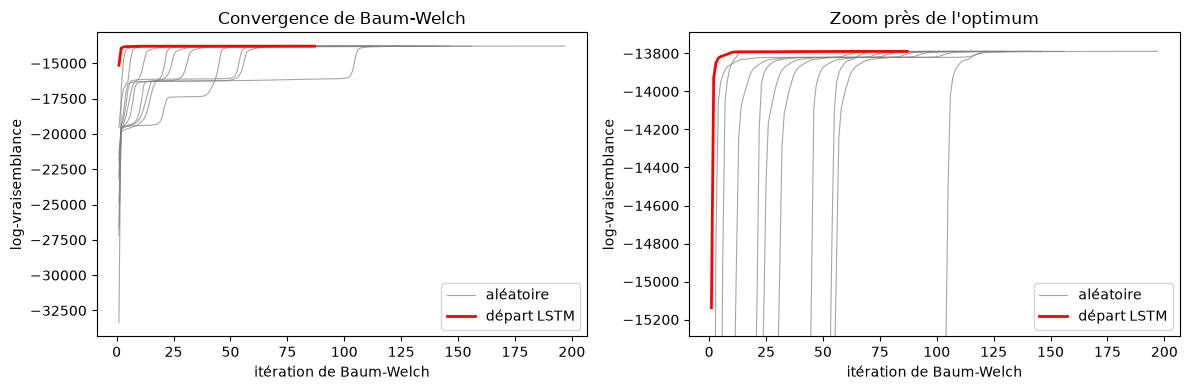

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, zoom in zip(axes, [False, True]):
    for s, c in courbes_alea.items():
        ax.plot(range(1, len(c) + 1), c, color="grey", lw=0.8, alpha=0.7, label="aléatoire" if s == 0 else None)
    ax.plot(range(1, len(courbe_lstm) + 1), courbe_lstm, color="red", lw=2, label="départ LSTM")
    ax.set_xlabel("itération de Baum-Welch"); ax.set_ylabel("log-vraisemblance"); ax.legend()
    if zoom:
        ax.set_ylim(ll_final_lstm - 1500, ll_final_lstm + 100); ax.set_title("Zoom près de l'optimum")
    else:
        ax.set_title("Convergence de Baum-Welch")
plt.tight_layout(); plt.savefig("../results/hmm_lstm_convergence.png", dpi=150); plt.show()

> **Interprétation :**
>
> - **À gauche :** les départs aléatoires (gris) partent très bas et restent souvent bloqués sur des **plateaux** (vers −19 500, −17 400, −16 200) : ce sont des **optimums locaux** dont ils ne sortent qu'au bout de 20 à 100 itérations. Le départ LSTM (rouge) part déjà en haut et **ne passe par aucun plateau**.
> - **À droite (zoom) :** le départ LSTM atteint presque l'optimum en **moins de 10 itérations**, puis fait de petits ajustements. Certaines courbes aléatoires n'y arrivent qu'après plus de 100 itérations.
>
> Avec plus d'états ou des données plus difficiles, un départ aléatoire pourrait **rester bloqué** sur un de ces plateaux. Le départ LSTM évite ce risque.

## 15. Robustesse

### Cellule 25 – Le résultat dépend-il de la graine du LSTM ?
Le LSTM part lui aussi de poids aléatoires. On le **ré-entraîne avec 2 autres graines** et on refait toute la chaîne (états cachés → k-means → π, A, μ, Σ → Baum-Welch). On regarde si les régimes du LSTM sont les mêmes et si le HMM final est le même.

In [25]:
def chaine_complete(graine):
    torch.manual_seed(graine)
    m = ReseauLSTM(len(ENTREES), H)
    entrainer(m, X_fit, Y_fit, X_val, Y_val, graine=graine, afficher=False)
    m.eval()
    with torch.no_grad():
        Hs = StandardScaler().fit_transform(m(torch.tensor(W_tr))[1].numpy())
    lab = KMeans(N, n_init=10, random_state=GRAINE).fit(Hs).labels_
    lab = np.argsort(np.argsort([obs_tr[lab == c, 1].mean() for c in range(N)]))[lab]
    cpt = np.zeros((N, N))
    for a, b in zip(lab[:-1], lab[1:]): cpt[a, b] += 1
    A_ = (cpt + 1) / (cpt + 1).sum(axis=1, keepdims=True)
    mu_ = np.array([obs_tr[lab == c].mean(axis=0) for c in range(N)])
    cov_ = np.array([np.cov(obs_tr[lab == c].T) for c in range(N)])
    h = hmm_depuis(np.bincount(lab, minlength=N) / len(lab), A_, mu_, cov_)
    l0 = h.score(X_train); h.fit(X_train)
    return lab, h, l0

rob = [{"graine LSTM": GRAINE, "accord des régimes LSTM avec la graine 0 (%)": 100.0, "logL départ": ll_depart_lstm,
        "logL finale": ll_final_lstm, "itérations": hmm_lstm.monitor_.iter,
        "μ volatilité finales": np.sort(hmm_lstm.means_[:, 1]).round(2)}]
for g in [1, 2]:
    lab_g, h_g, l0_g = chaine_complete(g)
    rob.append({"graine LSTM": g, "accord des régimes LSTM avec la graine 0 (%)": 100 * np.mean(lab_g == etiq),
                "logL départ": l0_g, "logL finale": h_g.score(X_train), "itérations": h_g.monitor_.iter,
                "μ volatilité finales": np.sort(h_g.means_[:, 1]).round(2)})
pd.DataFrame(rob).set_index("graine LSTM").round(1)

,accord des régimes LSTM avec la graine 0 (%),logL départ,logL finale,itérations,μ volatilité finales
graine LSTM,,,,,
0,100.0,-15137.2,-13789.0,87,"[-1.04, 0.08, 1.16]"
1,79.5,-15092.0,-13789.1,33,"[-1.04, 0.08, 1.16]"
2,86.7,-15625.9,-13789.0,86,"[-1.04, 0.08, 1.16]"


> **Interprétation :**
>
> - Les régimes trouvés par le LSTM **varient un peu** selon la graine : 80 % et 87 % d'accord avec la graine 0. C'est normal : les frontières entre régimes sont floues (silhouette faible).
> - Mais le **HMM final est le même** dans les 3 cas : même log-vraisemblance (−13 789) et mêmes moyennes de volatilité (−1,04 ; 0,08 ; 1,16).
> - Les 3 départs LSTM restent proches de l'optimum (entre −15 626 et −15 092), et Baum-Welch converge en 33 à 87 itérations.
>
> Conclusion : la méthode est **robuste**. Le résultat ne dépend pas d'un tirage chanceux.

## 16. Régimes finaux et prédiction sans look-ahead

### Cellule 26 – Interprétation économique des régimes du HMM final
Chaque bougie du train est attribuée à son régime le plus probable (Viterbi). On résume les valeurs **brutes** (en %) de chaque régime et la durée moyenne donnée par la matrice de transition.

In [26]:
A_fin, pi_fin = hmm_lstm.transmat_, hmm_lstm.startprob_
etats_vit = hmm_lstm.predict(X_train)
regimes = pd.DataFrame({
    "part du temps (%)": 100 * np.bincount(etats_vit, minlength=N) / len(etats_vit),
    "rendement moyen (%)": [100 * feat["rendement"].values[:k][etats_vit == c].mean() for c in range(N)],
    "rendement annualisé (%)": [100 * feat["rendement"].values[:k][etats_vit == c].mean() * PAR_JOUR * 365 for c in range(N)],
    "volatilité moyenne (%)": [100 * feat["volatilite"].values[:k][etats_vit == c].mean() for c in range(N)],
    "durée moyenne (jours)": 1 / (1 - np.diag(A_fin)) / PAR_JOUR}, index=NOMS)
print("Accord entre les régimes du LSTM et ceux du HMM final (Viterbi) :",
      f"{100 * np.mean(etats_vit[i_tr] == etiq):.1f} %")
regimes.round(3)

Accord entre les régimes du LSTM et ceux du HMM final (Viterbi) : 68.9 %


,part du temps (%),rendement moyen (%),rendement annualisé (%),volatilité moyenne (%),durée moyenne (jours)
Calme,36.313,0.017,18.888,1.167,40.385
Intermédiaire,34.146,0.008,8.890,1.865,17.603
Agité,29.541,0.080,87.483,3.152,28.325


> **Interprétation :**
>
> Régimes du HMM final, en valeurs brutes :
> - **Calme** : volatilité **1,2 %**, 36 % du temps, dure **40 jours** en moyenne ;
> - **Intermédiaire** : volatilité **1,9 %**, 34 % du temps, dure **18 jours** ;
> - **Agité** : volatilité **3,2 %**, 30 % du temps, dure **28 jours**, et le meilleur rendement annualisé (**87 %**) : ce régime contient les bulles (2017, 2021) autant que les krachs.
>
> Les régimes du HMM sont **plus longs** que ceux du LSTM (18 à 40 jours au lieu de 3 à 6) : le HMM lisse les changements. Les deux découpages sont d'accord pour **69 %** des bougies.

### Cellule 27 – Filtre forward sur le test et prédiction du régime suivant
Comme dans le notebook 04, on utilise le **filtre forward** `P(S_t | x_1..x_t)`, qui n'utilise **que le passé** (pas de look-ahead), puis la prédiction pour la bougie suivante `P(S_{t+1}) = filtre_t · A`. Le modèle a été appris sur le train seulement.

On compare deux modèles :
- **LSTM seul** : les paramètres donnés par le LSTM, **sans** Baum-Welch ;
- **LSTM + Baum-Welch** : le HMM final.

In [27]:
def filtre_forward(X, pi, A, mu, cov):
    T = len(X)
    emis = np.column_stack([multivariate_normal(mu[i], cov[i], allow_singular=True).pdf(X) for i in range(len(pi))])
    F = np.zeros((T, len(pi)))
    f = pi * emis[0]; F[0] = f / f.sum()
    for t in range(1, T):
        f = (F[t - 1] @ A) * emis[t]; F[t] = f / f.sum()
    return F

X_tout = np.vstack([X_train, X_test])
modeles_test = {"LSTM seul": (pi_lstm, A_lstm, mu_lstm, cov_lstm),
                "LSTM + Baum-Welch": (pi_fin, A_fin, hmm_lstm.means_, hmm_lstm.covars_)}
resultats = {}
for nom, (p_, A_, m_, c_) in modeles_test.items():
    F_test = filtre_forward(X_tout, p_, A_, m_, c_)[k:]
    P_next = F_test @ A_
    r = feat.iloc[k:][["Close", "rendement"]].copy()
    r["regime_actuel"] = [NOMS[i] for i in F_test.argmax(axis=1)]
    r["regime_predit"] = [NOMS[i] for i in P_next.argmax(axis=1)]
    r["p_changement"] = 1 - P_next[np.arange(len(P_next)), F_test.argmax(axis=1)]
    r["rendement_suivant"] = r["rendement"].shift(-1)
    resultats[nom] = r.iloc[:-1]
res = resultats["LSTM + Baum-Welch"]
display(res[["rendement", "regime_actuel", "regime_predit", "p_changement"]].tail(6).round(4))
pd.DataFrame({nom: r["regime_actuel"].value_counts(normalize=True).reindex(NOMS).fillna(0) * 100
              for nom, r in resultats.items()}).round(1).rename_axis("part du test (%)")

,rendement,regime_actuel,regime_predit,p_changement
Date,,,,
2026-10-29 16:00:00,-0.0474,Calme,Calme,0.0083
2026-10-30 00:00:00,0.0025,Calme,Calme,0.0083
2026-10-30 08:00:00,-0.0072,Calme,Calme,0.0083
2026-10-30 16:00:00,-0.0033,Calme,Calme,0.0083
2026-10-31 00:00:00,-0.0002,Calme,Calme,0.0083
2026-10-31 08:00:00,0.0034,Calme,Calme,0.0083


,LSTM seul,LSTM + Baum-Welch
part du test (%),,
Calme,75.1,76.5
Intermédiaire,24.9,21.9
Agité,0.0,1.6


> **Interprétation :**
>
> - Sur les dernières bougies d'octobre 2026, le marché est **Calme** et le modèle prévoit qu'il le reste, avec une probabilité de changer de seulement **0,8 %**, même après la baisse de −4,7 % du 29 octobre.
> - **Répartition du test :** environ **75 % Calme** et 22 à 25 % Intermédiaire. Le régime Agité représente **1,6 %** du test avec le HMM final, et **0 %** avec les paramètres du LSTM seul. La période 2024-2026 est beaucoup plus calme que le train.

### Cellule 28 – Le régime prédit renseigne-t-il sur la bougie suivante ?
Pour chaque régime prédit : nombre de bougies, rendement moyen et **volatilité réelle** (écart-type) de la bougie suivante. Si les régimes ont un sens, la bougie suivante doit être **plus agitée** quand le modèle prédit « Agité ».

In [28]:
for nom, r in resultats.items():
    s = r.groupby("regime_predit")["rendement_suivant"].agg(["count", "mean", "std"]).reindex(NOMS)
    s.columns = ["nb de bougies", "rendement suivant moyen", "écart-type du rendement suivant"]
    print(nom); display(s.round(5))

LSTM seul


,nb de bougies,rendement suivant moyen,écart-type du rendement suivant
regime_predit,,,
Calme,2259.0,0.00012,0.01271
Intermédiaire,749.0,0.00044,0.01603
Agité,NaN,NaN,NaN


LSTM + Baum-Welch


,nb de bougies,rendement suivant moyen,écart-type du rendement suivant
regime_predit,,,
Calme,2302,0.00011,0.01292
Intermédiaire,659,0.00032,0.01569
Agité,47,0.00261,0.01525


> **Interprétation :**
>
> - Quand le régime prédit est **Calme**, la bougie suivante a un écart-type de **1,27 à 1,29 %** ; quand il est **Intermédiaire**, **1,57 à 1,60 %**. Le régime prédit annonce bien une bougie suivante **plus ou moins agitée** : le modèle prévoit le **risque**.
> - Le rendement moyen est un peu plus élevé en Intermédiaire, mais l'écart est minuscule devant l'écart-type : **le régime ne prévoit pas la direction** du prix.
> - **Agité** n'est prédit que **47 fois** (HMM final) et **jamais** par le LSTM seul : c'est trop peu pour conclure sur ce régime pendant le test.

### Cellule 29 – Calibration de la probabilité de changement de régime
Le HMM donne à chaque bougie une probabilité de **changer de régime** à la bougie suivante. On la compare à la fréquence **réelle** des changements, par quartiles de probabilité.

In [29]:
r = res.copy()
r["changement_reel"] = (r["regime_actuel"].shift(-1) != r["regime_actuel"]).astype(int)
r = r.iloc[:-1]
r["classe"] = pd.qcut(r["p_changement"], 4, duplicates="drop")
r.groupby("classe", observed=True).agg(proba_predite=("p_changement", "mean"),
                                       frequence_reelle=("changement_reel", "mean"),
                                       n=("changement_reel", "size")).round(4)

,proba_predite,frequence_reelle,n
classe,,,
"(0.008252800000000001, 0.00825382]",0.0083,0.0000,752
"(0.00825382, 0.00835693]",0.0083,0.0000,752
"(0.00835693, 0.0201549]",0.0106,0.0013,751
"(0.0201549, 0.496586]",0.0798,0.0439,752


> **Interprétation :**
>
> - Dans les 3 premiers quartiles, le modèle annonce environ **1 %** de chances de changer de régime, et la réalité est entre **0 et 0,1 %** : le modèle est un peu trop prudent.
> - Dans le dernier quartile, il annonce **8 %** et la réalité est de **4,4 %** : il surestime les changements, mais il **les classe bien**. Presque tous les vrais changements arrivent quand le modèle les juge les plus probables.

### Cellule 30 – Graphique des régimes sur le test
Prix du test colorié selon le régime filtré (sans look-ahead) par le HMM initialisé par le LSTM. Sauvegardé dans `results/hmm_lstm_regimes_test.png`.

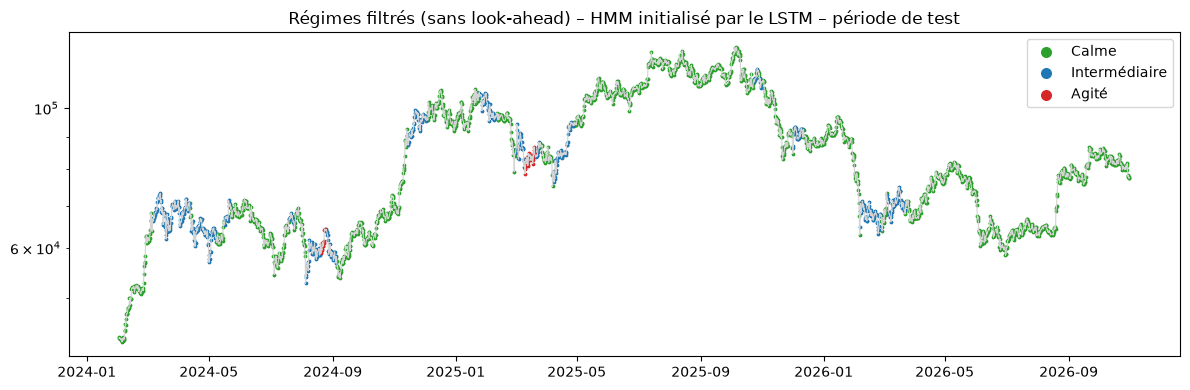

In [30]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(res.index, res["Close"], color="lightgrey", lw=0.8)
for nom in NOMS:
    sel = res["regime_actuel"] == nom
    ax.scatter(res.index[sel], res["Close"][sel], s=3, color=COULEURS[nom], label=nom)
ax.set_yscale("log"); ax.legend(markerscale=4)
ax.set_title("Régimes filtrés (sans look-ahead) – HMM initialisé par le LSTM – période de test")
plt.tight_layout(); plt.savefig("../results/hmm_lstm_regimes_test.png", dpi=150); plt.show()

> **Interprétation :**
>
> - Le **vert (Calme)** domine le test, y compris pendant de fortes hausses (fin 2024, mi-2025) et la baisse de fin 2025 : les régimes décrivent **la volatilité, pas la direction**.
> - Le **bleu (Intermédiaire)** apparaît dans les périodes plus agitées : printemps 2024, fin 2024 - début 2025, février-mars 2026.
> - Le **rouge (Agité)** apparaît à deux moments : **début août 2024** et **mars 2025**, deux chutes brutales du marché. Le modèle les détecte **sans regarder le futur**.
>
> Ce découpage est quasiment le même que celui du notebook 04, ce qui est logique puisque les deux HMM convergent vers le même optimum.

## 17. Sauvegarde et conclusion

### Cellule 31 – Sauvegarde des paramètres
On enregistre les paramètres **de départ** (LSTM) et **finaux** (après Baum-Welch) dans `results/hmm_lstm_parametres.json`, pour le rapport et le dashboard.

In [31]:
sortie = {"etats": NOMS, "observations": colonnes, "entrees_lstm": ENTREES, "fenetre_bougies": L,
          "depart_lstm": {"pi": pi_lstm.tolist(), "A": A_lstm.tolist(), "mu": mu_lstm.tolist(), "cov": cov_lstm.tolist()},
          "final_baum_welch": {"pi": pi_fin.tolist(), "A": A_fin.tolist(), "mu": hmm_lstm.means_.tolist(),
                               "cov": hmm_lstm.covars_.tolist()},
          "logL_train": {"depart": ll_depart_lstm, "final": ll_final_lstm}, "iterations": int(hmm_lstm.monitor_.iter)}
with open("../results/hmm_lstm_parametres.json", "w", encoding="utf-8") as f:
    json.dump(sortie, f, ensure_ascii=False, indent=2)
print("Sauvegardé : results/hmm_lstm_parametres.json")

Sauvegardé : results/hmm_lstm_parametres.json


> **Interprétation :**
>
> Les paramètres de départ (LSTM) et finaux (après Baum-Welch) sont enregistrés dans `results/hmm_lstm_parametres.json`. Ils peuvent être relus pour le rapport ou le dashboard sans réentraîner le LSTM.

### Conclusion

| Étape | Résultat |
|---|---|
| Entrées du LSTM | rendement + variables de volatilité choisies par la feature selection (`volatilite`, `vol_3j`, `amplitude`), transformées en N(0, 1) |
| Ce que le LSTM a appris | il prévoit la **volatilité du lendemain 20 % mieux** que la moyenne ; il ne prévoit pas la direction du prix |
| Régimes du LSTM | Calme (1,2 %), Intermédiaire (2,0 %), Agité (3,7 % ; rendement négatif, proche de la « Panique ») |
| π et A | estimés en **comptant** les transitions des régimes du LSTM (maximum de vraisemblance + lissage de Laplace) ; structure en « échelle » : jamais de saut direct Calme ↔ Agité |
| μ_k, Σ_k | moyennes et covariances des observations dans chaque régime du LSTM |
| Départ du HMM | log-vraisemblance −15 137, contre −24 303 en moyenne pour un départ aléatoire |
| Baum-Welch | 87 itérations (130 en moyenne pour le hasard), même optimum final (−13 789), sans plateau d'optimum local |
| Robustesse | autres graines du LSTM → même HMM final |
| Test (sans look-ahead) | le régime prédit annonce le **risque** de la bougie suivante (écart-type 1,3 % en Calme contre 1,6 % en Intermédiaire) ; il ne prévoit pas la direction |

**Réponse à la question « pourquoi pas un départ aléatoire ? »** Les paramètres initiaux de la chaîne de Markov (π, A) et des lois d'émission (μ, Σ) ne sont plus tirés au hasard : ils sont **déduits de nos données** par un LSTM qui a appris la dynamique de la volatilité du Bitcoin. Ce départ a un **sens économique** (les régimes correspondent aux crises connues), il est **reproductible**, il part **près de l'optimum** et il évite les plateaux d'optimum local. Le résultat final rejoint celui du notebook 04, ce qui **valide** les deux approches.

**Limites :**
- les régimes du LSTM dépendent un peu de sa graine (80 à 87 % d'accord), même si le HMM final est identique ;
- Baum-Welch rallonge beaucoup les régimes (3-6 jours pour le LSTM, 18-40 jours pour le HMM) ;
- le régime Agité est très rare dans le test (2024-2026 est une période calme).